# Importancia de variables

**Pregunta:** ¿en qué variables se apoya el clasificador y tiene sentido físico? La regla comercial decide por **calibre** (Extra/Primera/Segunda/Tercera) y por **defecto y color** (Fábrica): si el modelo se apoya en otra cosa, hay que sospechar (atajos de contexto, ruido).

| Método | Qué mide | Cuidado |
|---|---|---|
| **Permutación fuera de muestra** | Cuánto cae el F1 macro al barajar una variable en el pliegue retenido de la CV (solo train) | Subestima variables redundantes |
| **Permutación agrupada por dimensión** | Lo mismo, barajando juntas Calibre, Forma, Color, Defecto o Textura; también por clase | Es la lectura más robusta con pocos datos |
| **Impureza de Random Forest** | Reducción de impureza en los árboles | Sesgada hacia variables continuas y correlacionadas |
| **Información mutua** | Dependencia con la categoría, sin modelo | No ve interacciones |
| **Control de ruido** | Una columna aleatoria: referencia de "importancia por azar" | Una variable solo cuenta si la supera **y** ayuda en ≥ 60 % de los pliegues |

**Se calcula solo con train** (el conjunto de prueba no se usa). Con `MODO_DEMO = True` los resultados son de imágenes sintéticas: validan el flujo, **no** son conclusiones.

In [3]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import importancia as im, fe_experimentos as fx, extraer_features as ef, ingesta, particion

MODO_DEMO = False                      # <-- False con los datos reales
RAW  = ROOT / "data" / ("demo/raw" if MODO_DEMO else "raw")
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
cfg = ef.cargar_cfg()
print("Configuración de importancia:", im.cfg_importancia(cfg))

Configuración de importancia: {'modelos': ['rf', 'logreg'], 'conjunto': 'A+C', 'n_repeats': 5, 'top_k': 10, 'ruido_control': True}


## 1. Datos (se generan los prerrequisitos que falten)

In [4]:
if not (PROC / "indice_frutos.csv").exists():  ingesta.main(RAW, PROC)
if not (PROC / "particion.csv").exists():      particion.main(PROC, forzar=False)
if not (PROC / "features_frutos.csv").exists(): ef.main(RAW, PROC, n_jobs=1)
df = fx.cargar_datos(PROC, cfg)
tr = next(iter(fx.dividir(df)))
cuenta = tr["y"].value_counts()
HAY_CLASES = len(cuenta) >= 2 and cuenta.min() >= 5
print("Train por categoría:", cuenta.to_dict())
if not HAY_CLASES:
    print("[AVISO] Se necesitan >= 2 categorías con >= 5 frutos en train: se omiten las secciones 2 a 6.")

Train por categoría: {'Extra': 77, 'Primera': 71, 'Segunda': 71, 'Fabrica': 70, 'Tercera': 70}


## 2. Calcular (permutación OOF + agrupada + impureza + información mutua)
Puede tardar uno o dos minutos: 15 pliegues (5 × 3 semillas) × cada modelo × cada variable × repeticiones.

In [5]:
if HAY_CLASES:
    R = im.ejecutar(PROC, cfg, verbose=True)
    modelos = list(R["perm"]); principal = modelos[0]

Train: 359 frutos | 36 variables (incl. control de ruido: True) | CV 5 pliegues x 3 semillas | conjunto A+C
  rf: top3 = circularidad (0.030), L_p10 (0.014), long_polar_px (0.013)
  logreg: top3 = circularidad (0.097), a_std (0.087), diam_ecu_px (0.083)
Registro guardado en C:\Users\angeljoel\Documents\CICLO IV\TI2\LemonQualityClassification\logs\importancia_runs\20261030_184617


## 3. Importancia por variable
**Qué buscar:** (1) barras que **superan la línea punteada** (umbral del control de ruido); (2) **desviación** (la barra de error): con pocos frutos suele ser tan grande como la media; (3) el color de la barra: ¿predominan Calibre, Defecto y Color?

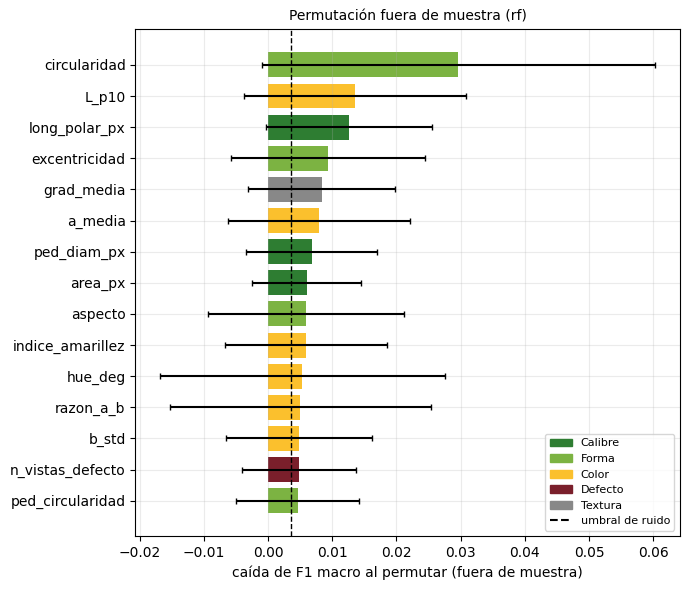

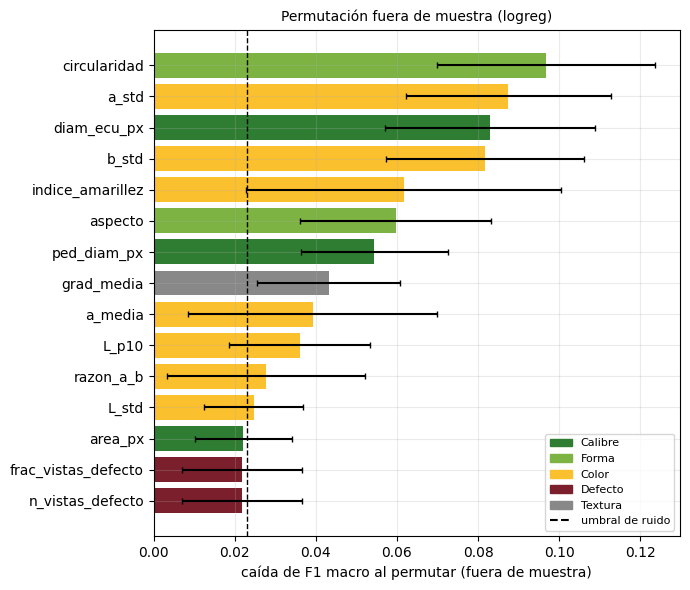

,media,std,pct_pliegues_ayuda,pct_top10,dimension,supera_ruido
variable,,,,,,
circularidad,0.030,0.031,93.333,86.667,Forma,True
L_p10,0.014,0.017,73.333,66.667,Color,True
long_polar_px,0.013,0.013,80.000,60.000,Calibre,True
excentricidad,0.009,0.015,60.000,40.000,Forma,True
grad_media,0.008,0.011,73.333,53.333,Textura,True
a_media,0.008,0.014,66.667,53.333,Color,True
ped_diam_px,0.007,0.010,80.000,40.000,Calibre,True
area_px,0.006,0.008,80.000,40.000,Calibre,True
aspecto,0.006,0.015,60.000,33.333,Forma,True


rf: variables que se distinguen del ruido = 15 de 35
logreg: variables que se distinguen del ruido = 12 de 35


In [6]:
if HAY_CLASES:
    for m in modelos:
        fig = im.fig_permutacion(R["perm"][m], f"Permutación fuera de muestra ({m})"); plt.show()
    t = R["perm"][principal].copy()
    display(t.head(12)[["media", "std", "pct_pliegues_ayuda", f"pct_top{R['cfg']['top_k']}", "dimension", "supera_ruido"]].round(3))
    for m in modelos:
        print(f"{m}: variables que se distinguen del ruido = {int(R['perm'][m]['supera_ruido'].sum())} de {len(R['perm'][m]) - 1}")

## 4. Importancia por dimensión
Se barajan **juntas** todas las variables de una dimensión. Por eso captura lo que la importancia individual pierde cuando varias variables dicen lo mismo (diámetro en px y en mm, área, categoría por calibre…).
- **Columnas = clases:** ¿el **Calibre** sostiene Extra/Primera/Segunda/Tercera y el **Defecto/Color** sostienen Fábrica, como dicta la regla comercial?
- **`redundancia` = caída del grupo / suma de caídas individuales:** > 1 significa información compartida entre variables de la dimensión.

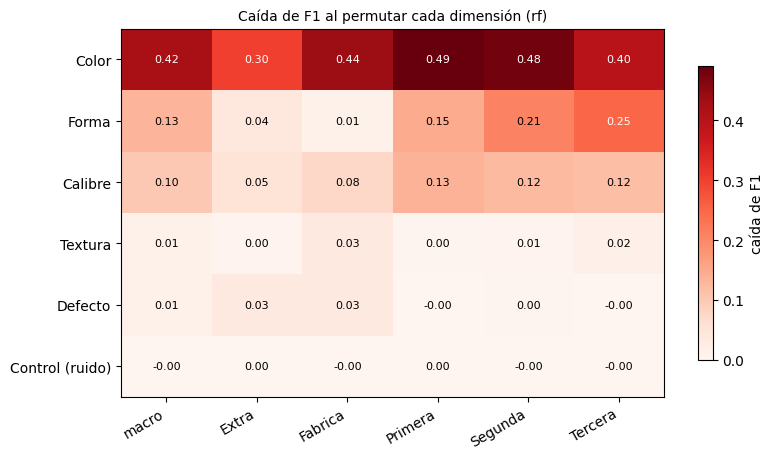

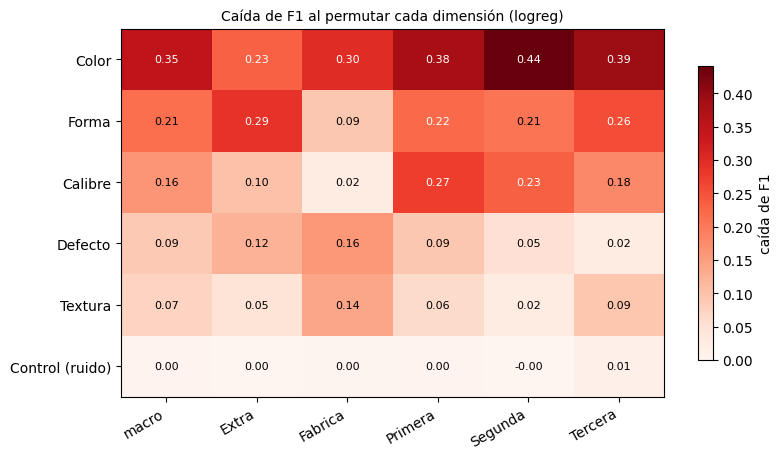

clase,Extra,Fabrica,Primera,Segunda,Tercera,macro,suma_individual,redundancia
dimension,,,,,,,,
Color,0.299,0.437,0.491,0.479,0.400,0.422,0.046,9.108
Forma,0.037,0.013,0.147,0.208,0.249,0.131,0.054,2.433
Calibre,0.050,0.076,0.135,0.124,0.118,0.101,0.025,3.967
Textura,0.004,0.034,0.004,0.006,0.015,0.012,0.011,1.117
Defecto,0.034,0.033,-0.004,0.003,-0.004,0.012,0.011,1.126
Control (ruido),0.001,-0.002,0.002,-0.002,-0.005,-0.001,0.000,NaN


In [7]:
if HAY_CLASES:
    for m in modelos:
        im.fig_dimensiones(R["dim_tabla"][m], f"Caída de F1 al permutar cada dimensión ({m})"); plt.show()
    display(R["dim_tabla"][principal].round(3))

## 5. Consenso entre métodos
Si los métodos coinciden, la conclusión es robusta; si no, **desconfiar de la variable concreta** y quedarse con la dimensión. El *rango medio* promedia el puesto de cada variable en cada método (menor = más importante).

In [8]:
if HAY_CLASES:
    display(R["consenso"].head(15).round(3))
    print("Acuerdo entre métodos (correlación de Spearman de los rangos):"); display(R["acuerdo"].round(2))
    a = R["acuerdo"].to_numpy(); print("Acuerdo medio:", round(float(np.nanmean(a[~np.eye(len(a), dtype=bool)])), 2))

,perm_rf,perm_logreg,impureza_rf,info_mutua,rango_medio,dimension
variable,,,,,,
circularidad,0.030,0.097,0.066,0.548,2.25,Forma
razon_a_b,0.005,0.028,0.079,0.628,6.25,Color
L_p10,0.014,0.036,0.051,0.430,7.25,Color
a_std,0.004,0.087,0.041,0.529,8.25,Color
ped_diam_px,0.007,0.054,0.045,0.409,8.50,Calibre
indice_amarillez,0.006,0.062,0.028,0.622,9.00,Color
a_media,0.008,0.039,0.035,0.387,10.50,Color
b_std,0.005,0.082,0.047,0.324,10.75,Color
hue_deg,0.005,0.011,0.077,0.628,10.75,Color


Acuerdo entre métodos (correlación de Spearman de los rangos):


,perm_rf,perm_logreg,impureza_rf,info_mutua
perm_rf,1.00,0.44,0.67,0.39
perm_logreg,0.44,1.00,0.50,0.34
impureza_rf,0.67,0.50,1.00,0.74
info_mutua,0.39,0.34,0.74,1.00


Acuerdo medio: 0.51


## 6. ¿Tiene sentido físico?
| Dimensión | Esperado según la regla comercial | Observado | ¿Coherente? |
|---|---|---|---|
| Calibre | Domina Extra, Primera, Segunda y Tercera |Presenta importancia moderada, pero es ampliamente superado por el Color en todas las clases.|Parcialmente. Aporta, pero no "domina".|
| Defecto | Sostiene Fábrica |Su impacto es muy bajo en Random Forest (F1 cae apenas 0.03 para Fábrica).|No. El modelo casi no lo usa para identificar Fábrica.|
| Color | Sostiene Fábrica (amarillo) y aporta a Tercera |Domina absolutamente todas las clases de manera transversal, con caídas de F1 muy superiores al resto|No. Hay una sobre-dependencia en todas las categorías.|
| Forma / Textura | Apoyo; poco peso |La Textura tiene un impacto casi nulo, pero la Forma (circularidad) tiene un peso sorprendentemente alto.|Textura sí; Forma no (pesa mucho más del esperado).|
| Control (ruido) | Importancia ≈ 0 |La caída de F1 al permutar la variable de ruido es efectivamente 0.00.|Sí.|

**Señales de alarma:** una dimensión inesperada con peso alto (¿atajo de contexto? revisar deriva por lote/fecha en el notebook de Feature Engineering), el ruido con importancia alta (modelo inestable), o desacuerdo fuerte entre métodos.

## 7. Decisiones
| # | Pregunta | Evidencia | Decisión |
|---|---|---|---|
| 1 | ¿Las dimensiones importantes coinciden con las de la regla comercial? | §4, gráficos de permutación |No coinciden. El modelo encontró un "atajo de contexto". Usa el Color y la Forma para predecir clases que, comercialmente, deberían definirse por Calibre y Defectos.|
| 2 | ¿Qué variables se pueden descartar sin perder información (redundantes o al nivel del ruido)? | §3, §5, mapas de calor|Se pueden descartar las variables de la dimensión Textura, ya que su aporte a la caída de F1 es cercano a cero.|
| 3 | ¿Hay variables importantes que dependan de la sesión (brillo, color sin corregir)? | §3, gráficos de permutación|Sí. Hay alta dependencia de variables de color (L_p10, a_std, b_std), lo cual hace al modelo vulnerable a cambios de iluminación entre lotes o sesiones.|
| 4 | ¿Qué variables conviene medir mejor? (p. ej. calibre cerca de los límites, defecto) | §4 |Conviene rediseñar y medir mejor la extracción de Defectos. Actualmente el modelo no logra extraer señal útil de estas variables para identificar la clase Fábrica.|